<a href="https://colab.research.google.com/github/anupbagale/csv-data-to-image/blob/main/notebooks/01_image_to_csv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grayscale image to CSV and back

A grayscale image is a grid of numbers between 0 (black) and 255 (white). This notebook writes
those numbers to a CSV file, one image row per line, reads the file back and checks that the
image comes back exactly as it was.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

os.makedirs("output", exist_ok=True)   # the CSV and image files are written here

We use the camera image that comes with scikit-image. It is 512 x 512 pixels and already
grayscale, so there is nothing to download.

In [2]:
image = data.camera()
print("shape:", image.shape, " type:", image.dtype)

shape: (512, 512)  type: uint8


## The numbers behind the image

Here is a 12 x 12 pixel patch next to the man's eye, with the value of every pixel written on it.

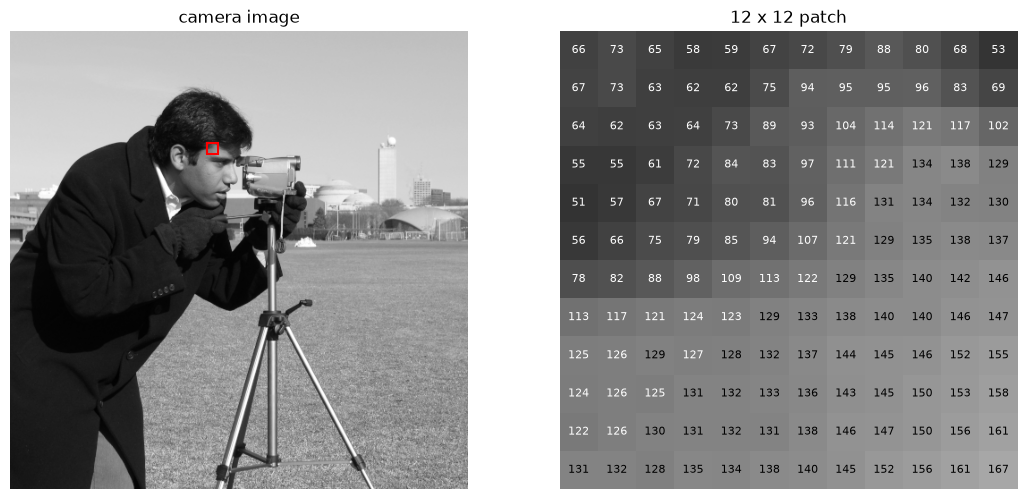

In [3]:
r, c = 125, 220
patch = image[r:r + 12, c:c + 12]

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].imshow(image, cmap="gray")
ax[0].add_patch(plt.Rectangle((c, r), 12, 12, fill=False, edgecolor="red", lw=1.5))
ax[0].set_title("camera image")
ax[0].axis("off")

ax[1].imshow(patch, cmap="gray", vmin=0, vmax=255)
for (i, j), v in np.ndenumerate(patch):
    ax[1].text(j, i, v, ha="center", va="center", fontsize=8,
               color="black" if v > 127 else "white")
ax[1].set_title("12 x 12 patch")
ax[1].axis("off")
plt.show()

## Writing the CSV file

Python's `csv` module writes one list of values per line. Passing `newline=""` to `open` stops
Windows from adding an empty line after every row.

In [4]:
import csv

csv_path = "output/camera.csv"
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    for row in image:
        writer.writerow(row)

with open(csv_path) as f:
    lines = f.readlines()
print("lines in the file:", len(lines))
print("first line starts with:", lines[0][:60], "...")

lines in the file: 512
first line starts with: 200,200,200,200,199,200,199,198,199,198,198,198,198,198,198, ...


## Reading it back

`np.loadtxt` reads the numbers into an array. Asking for `dtype=np.uint8` directly gives the same
type as the original image. (The first version of this notebook read the values as floats with
`np.genfromtxt` and converted them back with `cv2.convertScaleAbs`, which works but takes an extra
step.)

In [5]:
restored = np.loadtxt(csv_path, delimiter=",", dtype=np.uint8)
print("shape:", restored.shape, " type:", restored.dtype)
print("identical to the original:", np.array_equal(restored, image))

shape: (512, 512)  type: uint8
identical to the original: True


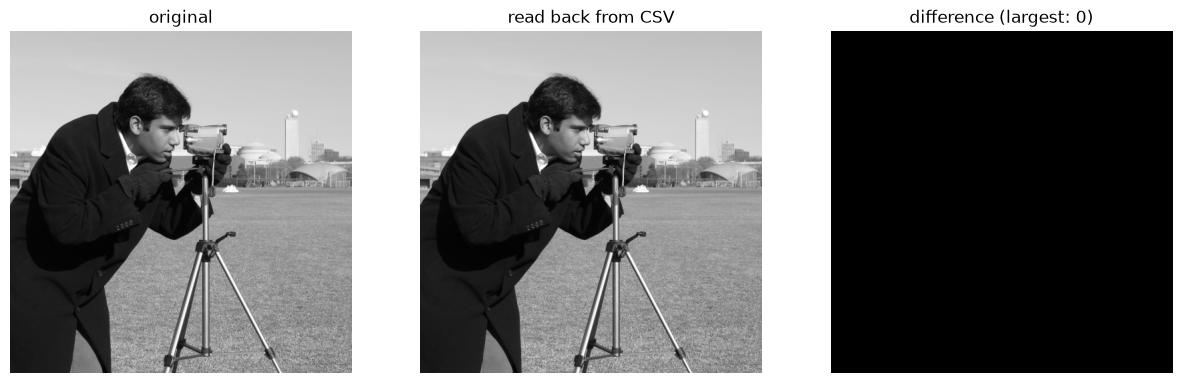

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image, cmap="gray"); ax[0].set_title("original")
ax[1].imshow(restored, cmap="gray"); ax[1].set_title("read back from CSV")
diff = np.abs(image.astype(int) - restored.astype(int))
ax[2].imshow(diff, cmap="gray", vmin=0, vmax=1)
ax[2].set_title(f"difference (largest: {diff.max()})")
for a in ax:
    a.axis("off")
plt.show()

## How big is the file?

A CSV file stores every value as text. A pixel value like `142` takes three characters plus a
comma, so it needs about four bytes instead of one. PNG, on the other hand, compresses the image.

In [7]:
cv2.imwrite("output/camera.png", image)

raw = image.size                      # one byte per pixel
csv_size = os.path.getsize(csv_path)
png_size = os.path.getsize("output/camera.png")

print(f"raw pixel data: {raw / 1024:7.0f} KB")
print(f"CSV file:       {csv_size / 1024:7.0f} KB  ({csv_size / raw:.1f} x raw)")
print(f"PNG file:       {png_size / 1024:7.0f} KB  ({png_size / raw:.2f} x raw)")

raw pixel data:     256 KB
CSV file:           932 KB  (3.6 x raw)
PNG file:           145 KB  (0.57 x raw)


CSV is a poor format for storing images, but it is useful when the pixel values need to be opened
in a spreadsheet, passed to a program that only reads text, or inspected by hand.